# Bangkok's PM2.5 Problem, 2016 to 2025: Seasonality, Long-term Trend, and the Role of Regional Biomass Burning

**2107540 Data Science for Environment and Sustainability, Project 1**
Kan Prangwattanakul (6732003021), Chulalongkorn University

---

### Environmental problem
Fine particulate matter (PM2.5) is Bangkok's most persistent air-quality problem. Every dry season the city's monitors report days above the Thai 24-hour standard, and the annual mean sits far above the WHO 2021 guideline.
Policy debate tends to blame either *local traffic* or *agricultural and forest burning*, but those claims are rarely tested with long-run monitoring data.

### Research questions
| # | Question | Analysis |
|---|---|---|
| RQ1 | How strongly does PM2.5 vary by season and between roadside and general-area stations? | EDA, paired tests |
| RQ2 | Has PM2.5 actually decreased between 2016 and 2025 once season and changes in which stations were reporting are controlled for? | Fixed-effects regression, Seasonal Mann-Kendall |
| RQ3 | How much of the month-to-month variation is linked to regional fires versus meteorology? | Anomaly correlation, regression with month fixed effects |
| RQ4 | How far is Bangkok from the Thai standards and the WHO guideline? | Compliance metrics |
| RQ5 *(optional ML)* | Can meteorology and fire activity predict monthly PM2.5 better than a seasonal baseline? | Ridge, Random Forest, Gradient Boosting, time-based validation |

### Data (all real, all public)
| Dataset | Provider | Resolution | Coverage used |
|---|---|---|---|
| PM2.5 monthly station reports (119 PDFs) | Pollution Control Department (PCD), Air4Thai | station-month | 12 Bangkok stations, 2016 to 2025 |
| ERA5 reanalysis (temperature, humidity, rain, wind, boundary-layer height) | ECMWF via Open-Meteo Historical Weather API | hourly, central Bangkok | 2016 to 2025 |
| Active-fire detections, MODIS Collection 6.1 | NASA FIRMS | each detection | Thailand, Cambodia, Myanmar, 2016 to 2025 |

In [1]:
import os, sys, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
import seaborn as sns
from scipy import stats
import statsmodels.formula.api as smf
import pymannkendall as mk

warnings.filterwarnings("ignore", category=FutureWarning)
ROOT = os.path.abspath(os.path.join(os.getcwd(), "..")) if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
sys.path.insert(0, os.path.join(ROOT, "src"))
RAW, PROC, FIG = (os.path.join(ROOT, p) for p in ("data/raw", "data/processed", "figures"))
os.makedirs(PROC, exist_ok=True); os.makedirs(FIG, exist_ok=True)
RESULTS = {}            # every headline number is stored here and exported to results.json

# ---- chart style: thin marks, recessive hairline grid, colour-blind-validated palette ----
INK, INK2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
C1, C2, C3 = "#2a78d6", "#eb6834", "#1baf7a"           # categorical slots 1-3 (validated all-pairs)
BLUES = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
SEQ = LinearSegmentedColormap.from_list("seq_blue", BLUES)
DIV = LinearSegmentedColormap.from_list("div", ["#2a78d6", "#e9e8e4", "#e34948"])
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
    "axes.titlesize": 11.5, "axes.titleweight": "bold", "axes.titlecolor": INK,
    "axes.titlelocation": "left", "lines.linewidth": 2, "legend.frameon": False, "figure.dpi": 110,
})
def save(fig, name):
    fig.savefig(os.path.join(FIG, name), dpi=200, bbox_inches="tight")
    plt.show()
print("Project root:", ROOT)

Project root: /home/claude/Environmental-DS-Project


---
## Part 1: Data Collection

### 1.1 PM2.5: Pollution Control Department (Air4Thai) monthly station reports
Air4Thai's online history service returns hourly data for only the most recent weeks, so a ten-year analysis cannot be built from it.
For long records, PCD publishes **one quality-checked report per station per year** (Download, then the monthly-summary table on the History page).
Each report is a one-page PDF table. For PM2.5 it gives, per month: the **maximum and minimum 24-hour mean**, **days above the standard / valid days**, and the **monthly mean** (µg/m³).

All 12 PCD Bangkok stations with reports were downloaded for 2016 to 2025 (119 files; station 03R starts in 2017), from
`https://air4thai.com/forweb/getReport.php?file=<STATION>_<YEAR>`.
Station codes ending in **R** are *roadside* stations and those ending in **T** are *general-area* stations, as PCD labels them.

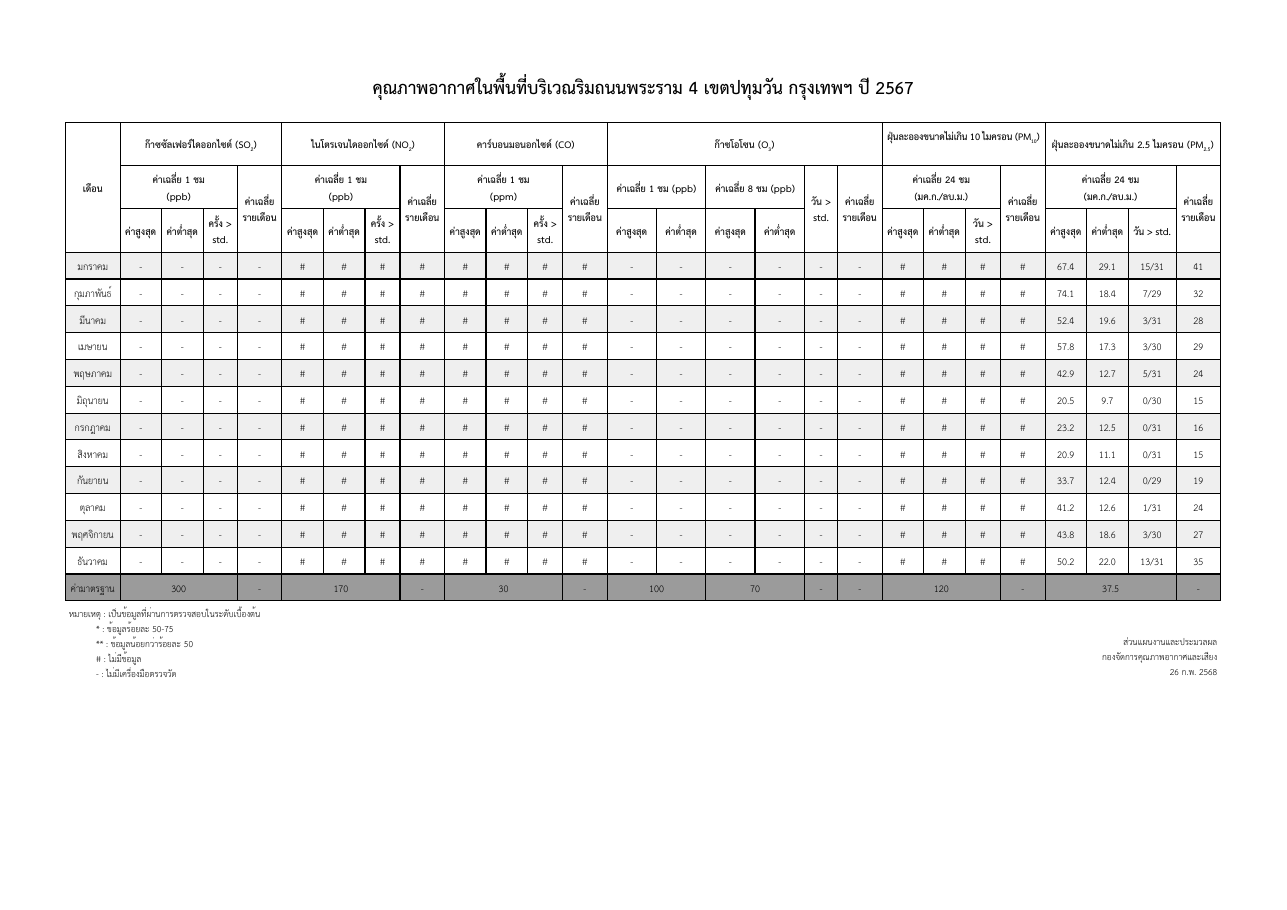

119 station-year PDF reports, e.g. ['02T_2016.pdf', '02T_2017.pdf', '02T_2018.pdf', '02T_2019.pdf'] ... ['61T_2024.pdf', '61T_2025.pdf']


In [2]:
from IPython.display import Image, display
display(Image(os.path.join(FIG, "fig00_raw_air4thai_report_50R_2024.png"), width=950))
pdfs = sorted(f for f in os.listdir(os.path.join(RAW, "air4thai_station_reports")) if f.endswith(".pdf"))
print(f"{len(pdfs)} station-year PDF reports, e.g. {pdfs[:4]} ... {pdfs[-2:]}")

*Figure 0: The raw input, Air4Thai report for Chulalongkorn Hospital roadside station (50R), 2024. The PM2.5 block is the right-most four columns.*

### 1.2 Meteorology: ERA5 reanalysis (Open-Meteo Historical Weather API)
Hourly ERA5 values for central Bangkok (13.75°N, 100.50°E), 2016-01-01 to 2025-12-31, local time (UTC+7):
2-m temperature, relative humidity, precipitation, 10-m wind speed and direction, **planetary boundary-layer height (BLH)** and surface pressure.
Request: `https://archive-api.open-meteo.com/v1/archive?latitude=13.75&longitude=100.52&start_date=2016-01-01&end_date=2025-12-31&hourly=temperature_2m,relative_humidity_2m,precipitation,wind_speed_10m,wind_direction_10m,boundary_layer_height,surface_pressure&models=era5&timezone=Asia/Bangkok&wind_speed_unit=ms&format=csv`

### 1.3 Regional fires: NASA FIRMS MODIS active-fire detections
The MODIS Collection 6.1 standard-processing country-year files (`https://firms.modaps.eosdis.nasa.gov/data/country/modis/<YEAR>/modis_<YEAR>_<COUNTRY>.csv`) for **Thailand, Cambodia and Myanmar**, 2016 to 2025.
MODIS is used rather than VIIRS because its sensor and algorithm were constant through the whole period, so year-to-year counts are comparable.
The raw files (about 80 MB) were reduced by `src/process_firms.py` (see Part 2.4). The filtered file is in the repository.

In [3]:
met_raw = pd.read_csv(os.path.join(RAW, "open_meteo/era5_bangkok_hourly_2016_2025.csv"), skiprows=3)
fire_raw = pd.read_csv(os.path.join(RAW, "firms_modis/firms_modis_vegfires_600km_bangkok_2016_2025.csv.gz"), parse_dates=["acq_date"])
print("ERA5 hourly:", met_raw.shape); display(met_raw.head(3))
print("FIRMS detections (filtered):", fire_raw.shape); display(fire_raw.head(3))

ERA5 hourly: (87672, 8)


,time,temperature_2m (°C),relative_humidity_2m (%),precipitation (mm),wind_speed_10m (m/s),wind_direction_10m (°),boundary_layer_height (m),surface_pressure (hPa)
0,2016-01-01T00:00,24.3,73,0.0,3.34,39,285.0,1016.3
1,2016-01-01T01:00,24.4,72,0.0,3.68,43,395.0,1015.9
2,2016-01-01T02:00,24.5,71,0.0,3.68,43,410.0,1015.5


FIRMS detections (filtered): (386979, 10)


,acq_date,acq_time,latitude,longitude,confidence,frp,daynight,satellite,country,dist_km
0,2016-01-01,342,16.5489,104.6097,72,10.4,D,Terra,Thailand,539.2
1,2016-01-01,342,17.8706,103.1796,66,10.0,D,Terra,Thailand,539.7
2,2016-01-01,342,17.4692,100.2136,56,8.5,D,Terra,Thailand,414.0


---
## Part 2: Data Cleaning and Transformation

### 2.1 Extracting PM2.5 from the PDF tables
The report layout changed several times between 2016 and 2025: page margins moved, some stations show SO2/CO blocks and others do not, and a few years have no PM2.5 analyser at all.
A fixed column order would therefore silently read PM10 as PM2.5. `src/parse_air4thai.py` avoids this by:
1. anchoring the 12 month rows on the Thai month labels and the **standard row** (ค่ามาตรฐาน);
2. clustering the x-position of every value on the page into columns;
3. accepting the right-most block as PM2.5 **only if the standard printed under it is 50 or 37.5 µg/m³** (the PM2.5 24-hour standards). A value of 120 means the right-most block is PM10, so the station-year has no PM2.5;
4. keeping PCD's data-completeness flags (`*` = 50 to 75 % valid data, `**` = under 50 %).

In [4]:
from parse_air4thai import parse
rows = []
for f in pdfs:
    code_, year = f[:-4].split("_")
    recs, std_val = parse(os.path.join(RAW, "air4thai_station_reports", f))
    for r in recs:
        r.update(station_code=code_, year=int(year), std_in_report=std_val, source_file=f)
        rows.append(r)
pm_raw = pd.DataFrame(rows)
pm_raw["completeness_flag"] = pm_raw["completeness_flag"].fillna("")
pm_raw.to_csv(os.path.join(PROC, "pm25_station_monthly_parsed.csv"), index=False)

no_pm = pm_raw.groupby(["station_code", "year"])["std_in_report"].first().loc[lambda s: s == 120].index.tolist()
print(f"{len(pm_raw)} station-month rows parsed from {len(pdfs)} PDFs")
print(f"Station-years with no PM2.5 analyser (standard row = 120 µg/m³, PM10): {len(no_pm)}")
print(no_pm)

# Validation against values read by eye from Figure 0 (50R, 2024)
check = pm_raw.query("station_code=='50R' and year==2024 and month in (1,6,12)")[["month","pm25_max24h","pm25_min24h","days_exceed","days_valid","pm25_mean"]]
expected = pd.DataFrame({"month":[1,6,12],"pm25_max24h":[67.4,20.5,50.2],"pm25_min24h":[29.1,9.7,22.0],"days_exceed":[15.,0.,13.],"days_valid":[31.,30.,31.],"pm25_mean":[41.,15.,35.]})
assert np.allclose(check.reset_index(drop=True).values, expected.values), "parser mismatch"
print("Parser output matches the PDF for 50R-2024 (Jan, Jun, Dec).")

1428 station-month rows parsed from 119 PDFs
Station-years with no PM2.5 analyser (standard row = 120 µg/m³, PM10): 13
[('02T', 2016), ('02T', 2017), ('02T', 2018), ('03R', 2017), ('10T', 2016), ('10T', 2017), ('11T', 2016), ('11T', 2017), ('12T', 2016), ('12T', 2017), ('12T', 2018), ('50R', 2016), ('53R', 2016)]
Parser output matches the PDF for 50R-2024 (Jan, Jun, Dec).


### 2.2 Quality control and station metadata
| Rule | Reason |
|---|---|
| Drop station-months flagged `**` (< 50 % valid data) | A monthly mean built on under half the month is not representative |
| Keep `*` (50 to 75 %) but carry the flag | Still usable; checked in sensitivity analysis |
| Logical check: min24h ≤ mean ≤ max24h | Detect transcription or parsing errors |
| Exceedance days are **not compared across 1 Jun 2023** | The Thai 24-h standard was tightened from 50 to 37.5 µg/m³ on 1 June 2023, so counts before and after are on different thresholds. For long-run comparison I use a *consistent* metric instead: **months whose maximum 24-h mean exceeded 37.5 µg/m³** |

In [5]:
pm = pm_raw.dropna(subset=["pm25_mean"]).copy()
n_all = len(pm)
pm = pm[pm["completeness_flag"] != "**"]
n_flag = n_all - len(pm)
bad = pm[(pm["pm25_min24h"] > pm["pm25_mean"]) | (pm["pm25_max24h"] < pm["pm25_mean"])]
print(f"Station-months with a PM2.5 mean: {n_all}; dropped (<50% data): {n_flag}; remaining: {len(pm)}")
print("Rows failing min <= mean <= max:"); display(bad[["station_code","year","month","pm25_min24h","pm25_mean","pm25_max24h","raw"]])

Station-months with a PM2.5 mean: 1177; dropped (<50% data): 17; remaining: 1160
Rows failing min <= mean <= max:


,station_code,year,month,pm25_min24h,pm25_mean,pm25_max24h,raw


After removing the under-50 % months, no row fails the logical check (the one inconsistent row in the raw parse was a `**` month). The check stays in the pipeline so that future data is validated the same way.
Station coordinates come from the Air4Thai station service (`/services/getNewAQI_JSON.php`). Station 11T has since closed and has no published coordinates.

In [6]:
pm = pm.drop(bad.index)
stations = pd.DataFrame([
    ("02T","Bansomdejchaopraya Rajabhat Univ., Thon Buri",13.732846,100.487662),
    ("03R","Kanchanaphisek Rd (Hwy 3902), Bang Khun Thian",13.636514,100.414262),
    ("05T","Thai Meteorological Dept., Bang Na",13.666183,100.605742),
    ("10T","NHA Khlong Chan, Bang Kapi",13.779873,100.646009),
    ("11T","NHA Huai Khwang sports ground",np.nan,np.nan),
    ("12T","Nonsi Witthaya School, Yan Nawa",13.70806667,100.5473333),
    ("50R","Chulalongkorn Hospital, Rama IV Rd",13.729852,100.536501),
    ("52R","Thonburi Power Sub-station, Intharaphitak Rd",13.727622,100.486568),
    ("53R","Chokchai Police Station, Lat Phrao Rd",13.7954248,100.5930298),
    ("54R","NHA Din Daeng, Din Daeng Rd",13.76251667,100.5502),
    ("59T","Government Public Relations Dept., Phaya Thai",13.783185,100.540489),
    ("61T","Bodindecha School, Wang Thonglang",13.769634,100.614567),
], columns=["station_code","name","lat","lon"])
stations["type"] = np.where(stations.station_code.str.endswith("R"), "Roadside", "General")
stations.to_csv(os.path.join(PROC, "stations.csv"), index=False)

pm["date"] = pd.to_datetime(dict(year=pm.year, month=pm.month, day=1))
pm = pm.merge(stations[["station_code","type"]], on="station_code")
pm["max_over_37_5"] = pm["pm25_max24h"] > 37.5
pm.to_csv(os.path.join(PROC, "pm25_station_monthly_clean.csv"), index=False)
RESULTS["n_station_months"] = int(len(pm)); RESULTS["n_stations"] = int(pm.station_code.nunique())
display(pm.groupby(["station_code","type"]).agg(months=("pm25_mean","size"), first=("date","min"), last=("date","max"), mean_pm25=("pm25_mean","mean")).round(1))

/tmp/ipykernel_15851/800854410.py:24: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(pm.groupby(["station_code","type"]).agg(months=("pm25_mean","size"), first=("date","min"), last=("date","max"), mean_pm25=("pm25_mean","mean")).round(1))


,,months,first,last,mean_pm25
station_code,type,,,,
02T,General,76,2019-09-01,2025-12-01,24.8
03R,Roadside,87,2018-10-01,2025-12-01,30.7
05T,General,113,2016-07-01,2025-12-01,22.6
10T,General,85,2018-11-01,2025-12-01,20.8
11T,General,78,2018-10-01,2025-04-01,22.6
12T,General,75,2019-09-01,2025-12-01,21.9
50R,Roadside,102,2017-06-01,2025-12-01,26.0
52R,Roadside,114,2016-07-01,2025-12-01,25.8
53R,Roadside,102,2017-06-01,2025-12-01,23.9


### 2.3 Meteorology: hourly to monthly, plus a derived dispersion variable
PM2.5 near the ground is diluted by the volume of air that mixes over the city. The standard measure is the **ventilation coefficient**:

$$VC = u_{10} \times BLH \quad [\text{m}^2\,\text{s}^{-1}]$$

where $u_{10}$ is the 10-m wind speed (m s⁻¹) and BLH is the boundary-layer height (m). A low VC means stagnant air.
I also compute the share of **calm hours** ($u_{10}$ < 1 m s⁻¹) and of **north-east to east winds** (0 to 90°), the dry-season monsoon direction.

**Data gap found:** the ERA5 feed has **no boundary-layer height from January to early July 2024** (4,368 hours). Those values are left missing, not filled in, and every BLH or VC analysis notes the gap.

In [7]:
met = met_raw.copy()
met.columns = ["time","t2m","rh","precip","ws","wd","blh","sp"]
met["time"] = pd.to_datetime(met["time"])
print("Missing values per column:"); print(met.isna().sum()[lambda s: s > 0])
gap = met[met.blh.isna()].time
print(f"BLH gap: {gap.min()} to {gap.max()}  ({len(gap)} hours)")
met["vc"] = met.ws * met.blh
met["calm"] = (met.ws < 1.0).astype(float)
met["ne_wind"] = met.wd.between(0, 90).astype(float)
met_m = met.set_index("time").resample("MS").agg(
    t2m=("t2m","mean"), rh=("rh","mean"), precip=("precip","sum"), ws=("ws","mean"),
    blh=("blh","mean"), vc=("vc","mean"), calm_share=("calm","mean"), ne_wind_share=("ne_wind","mean"))
# a month counts as having BLH only if at least 75% of its hours do
cov = met.set_index("time").blh.notna().resample("MS").mean()
met_m.loc[cov < 0.75, ["blh","vc"]] = np.nan
met_m.to_csv(os.path.join(PROC, "era5_bangkok_monthly.csv"))
display(met_m.head())

Missing values per column:
blh    4368
dtype: int64
BLH gap: 2024-01-01 07:00:00 to 2024-07-01 06:00:00  (4368 hours)


,t2m,rh,precip,ws,blh,vc,calm_share,ne_wind_share
time,,,,,,,,
2016-01-01,26.921505,75.247312,22.4,2.527500,510.356183,1358.729503,0.083333,0.184140
2016-02-01,27.129598,69.403736,4.8,2.666293,545.869253,1650.550000,0.054598,0.448276
2016-03-01,29.618145,73.875000,10.3,3.401694,607.836022,2127.124395,0.017473,0.096774
2016-04-01,31.607917,71.138889,10.3,3.800000,716.631944,2735.317917,0.004167,0.000000
2016-05-01,31.717876,70.194892,73.2,3.148723,725.060484,2481.812903,0.043011,0.021505


### 2.4 Fires: filtering and aggregation
Applied in `src/process_firms.py`:
* `type == 0`, which keeps *presumed vegetation fires* and drops volcanoes, static land sources and offshore flares;
* MODIS `confidence ≥ 30`, which drops low-confidence detections (the documented nominal and high classes);
* within **600 km** of central Bangkok (great-circle distance), which covers central, eastern and western Thailand, western Cambodia and southern Myanmar.

The detections are then aggregated to monthly **counts** and **total fire radiative power (FRP, MW)**, a proxy for the energy (and so the emissions) released. Results are split by distance (≤ 300 km and ≤ 600 km) and by country.

In [8]:
fire = fire_raw.copy()
fire["date"] = fire.acq_date.dt.to_period("M").dt.to_timestamp()
idx = pd.date_range("2016-01-01", "2025-12-01", freq="MS")
def monthly(mask, col="frp", how="size"):
    g = fire[mask].groupby("date")[col]
    return (g.size() if how == "size" else g.sum()).reindex(idx, fill_value=0)
fire_m = pd.DataFrame({
    "fires_300km": monthly(fire.dist_km <= 300),
    "fires_600km": monthly(fire.dist_km <= 600),
    "frp_600km":   monthly(fire.dist_km <= 600, how="sum"),
    "fires_TH":    monthly(fire.country == "Thailand"),
    "fires_KH":    monthly(fire.country == "Cambodia"),
    "fires_MM":    monthly(fire.country == "Myanmar"),
}, index=idx)
fire_m.index.name = "date"
fire_m.to_csv(os.path.join(PROC, "firms_monthly.csv"))
print("Detections kept by country:"); print(fire.country.value_counts())
display(fire_m.describe().round(0))

Detections kept by country:
country
Thailand    173892
Cambodia    157155
Myanmar      55932
Name: count, dtype: int64


,fires_300km,fires_600km,frp_600km,fires_TH,fires_KH,fires_MM
count,120.0,120.0,120.0,120.0,120.0,120.0
mean,801.0,3225.0,86162.0,1449.0,1310.0,466.0
std,1081.0,4458.0,134447.0,2053.0,2072.0,873.0
min,12.0,29.0,352.0,14.0,2.0,0.0
25%,53.0,136.0,1665.0,72.0,34.0,1.0
50%,182.0,494.0,8935.0,345.0,181.0,78.0
75%,1388.0,5556.0,140419.0,2310.0,2091.0,382.0
max,4358.0,16799.0,675583.0,8810.0,8056.0,4204.0


### 2.5 Analysis tables
Two tables are built:
* **Station-month panel** (`analysis_station_month.csv`): one row per station per month, used for the trend models and the ML.
* **City-month series** (`analysis_city_month.csv`): the mean across reporting stations, used to compare with the city-wide drivers.

Because stations joined the network at different times (59T, 61T and 54R in 2016; 02T and 12T only in late 2019), a plain city average mixes real change with changes in *which stations* are reporting.
The trend models therefore use **station fixed effects**, and the robustness check uses only the 5 stations that cover the whole period.

In [9]:
panel = pm.merge(met_m, left_on="date", right_index=True, how="left").merge(fire_m, left_on="date", right_index=True, how="left")
panel.to_csv(os.path.join(PROC, "analysis_station_month.csv"), index=False)
city = (pm.groupby("date").agg(pm25=("pm25_mean","mean"), n_stations=("pm25_mean","size"))
          .join(met_m).join(fire_m))
city["month"] = city.index.month; city["year"] = city.index.year
city.to_csv(os.path.join(PROC, "analysis_city_month.csv"))
print(panel.shape, city.shape)
display(city.head(3))

(1160, 29) (120, 18)


,pm25,n_stations,t2m,rh,precip,ws,blh,vc,calm_share,ne_wind_share,fires_300km,fires_600km,frp_600km,fires_TH,fires_KH,fires_MM,month,year
date,,,,,,,,,,,,,,,,,,
2016-01-01,34.333333,3,26.921505,75.247312,22.4,2.527500,510.356183,1358.729503,0.083333,0.184140,1879,7597,153721.9,2310,4974,313,1,2016
2016-02-01,44.666667,3,27.129598,69.403736,4.8,2.666293,545.869253,1650.550000,0.054598,0.448276,3150,13862,359675.6,5202,7861,799,2,2016
2016-03-01,41.666667,3,29.618145,73.875000,10.3,3.401694,607.836022,2127.124395,0.017473,0.096774,4358,15644,585155.0,8810,4462,2372,3,2016


---
## Part 3: Exploratory Data Analysis (EDA)
### 3.1 What data do we actually have?

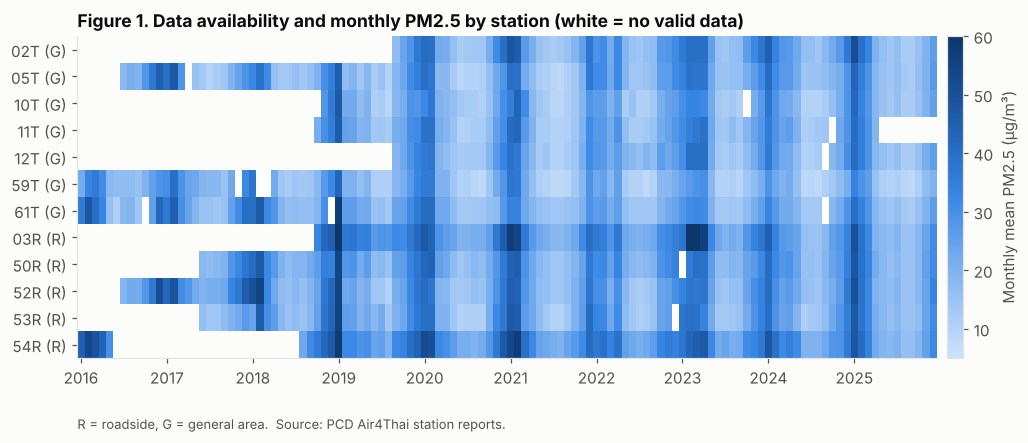

Months with >= 10 stations reporting: 85 of 120; median stations per month = 12


In [10]:
avail = pm.pivot_table(index="station_code", columns="date", values="pm25_mean", aggfunc="mean").reindex(columns=idx)
order = stations.sort_values(["type","station_code"]).station_code
avail = avail.reindex(order)
fig, ax = plt.subplots(figsize=(12, 3.8))
im = ax.imshow(avail.values, aspect="auto", cmap=SEQ, vmin=5, vmax=60, interpolation="nearest")
ax.set_yticks(range(len(avail))); ax.set_yticklabels([f"{s} ({'R' if s.endswith('R') else 'G'})" for s in avail.index])
yr_pos = [i for i, d in enumerate(idx) if d.month == 1]
ax.set_xticks(yr_pos); ax.set_xticklabels([idx[i].year for i in yr_pos]); ax.grid(False)
cb = fig.colorbar(im, ax=ax, pad=0.01); cb.set_label("Monthly mean PM2.5 (µg/m³)")
ax.set_title("Figure 1. Data availability and monthly PM2.5 by station (white = no valid data)")
ax.text(0, -0.22, "R = roadside, G = general area.  Source: PCD Air4Thai station reports.", transform=ax.transAxes, color=INK2, fontsize=8.5)
save(fig, "fig01_data_availability.png")
cov_city = city.n_stations
print(f"Months with >= 10 stations reporting: {(cov_city>=10).sum()} of {len(cov_city)}; median stations per month = {cov_city.median():.0f}")

**Reading Figure 1:** the network grew in two steps, in 2017 and in late 2018 to 2019. Instrument outages show up as white gaps, mostly in 2016 to 2018. The dark bands every January make the seasonal cycle visible even before any analysis.

### 3.2 Distribution by station

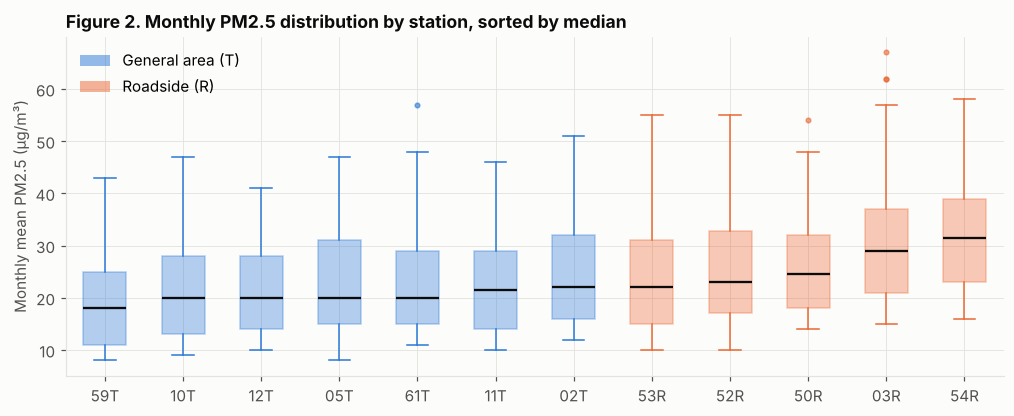

,count,mean,std,min,25%,50%,75%,max
station_code,,,,,,,,
59T,117.0,19.4,8.6,8.0,11.0,18.0,25.0,43.0
10T,85.0,20.8,9.1,9.0,13.0,20.0,28.0,47.0
12T,75.0,21.9,8.9,10.0,14.0,20.0,28.0,41.0
05T,113.0,22.6,10.0,8.0,15.0,20.0,31.0,47.0
61T,117.0,23.0,9.5,11.0,15.0,20.0,29.0,57.0
11T,78.0,22.6,9.4,10.0,14.0,21.5,29.0,46.0
02T,76.0,24.8,10.4,12.0,16.0,22.0,32.0,51.0
53R,102.0,23.9,10.3,10.0,15.0,22.0,31.0,55.0
52R,114.0,25.8,10.7,10.0,17.0,23.0,32.8,55.0


In [11]:
st_order = pm.groupby("station_code").pm25_mean.median().sort_values().index
fig, ax = plt.subplots(figsize=(11, 4))
for i, s in enumerate(st_order):
    d = pm[pm.station_code == s].pm25_mean
    col = C2 if s.endswith("R") else C1
    bp = ax.boxplot(d, positions=[i], widths=0.55, patch_artist=True, showfliers=True,
                    medianprops=dict(color=INK, lw=1.5), boxprops=dict(facecolor=col, alpha=0.35, edgecolor=col),
                    whiskerprops=dict(color=col), capprops=dict(color=col), flierprops=dict(marker="o", ms=3, mfc=col, mec=col, alpha=0.6))
ax.set_xticks(range(len(st_order))); ax.set_xticklabels(st_order)
ax.set_ylabel("Monthly mean PM2.5 (µg/m³)")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(facecolor=C1, alpha=0.5, label="General area (T)"), Patch(facecolor=C2, alpha=0.5, label="Roadside (R)")], loc="upper left")
ax.set_title("Figure 2. Monthly PM2.5 distribution by station, sorted by median")
save(fig, "fig02_station_distribution.png")
display(pm.groupby("station_code").pm25_mean.describe().round(1).loc[st_order])

**Reading Figure 2:** the five highest-median stations are exactly the five roadside stations, led by 54R (Din Daeng Road) and 03R (Kanchanaphisek Road). 59T (Phaya Thai, general area) is the cleanest.
Every station has a long upper tail, which comes from the dry-season months.

### 3.3 Seasonal cycle

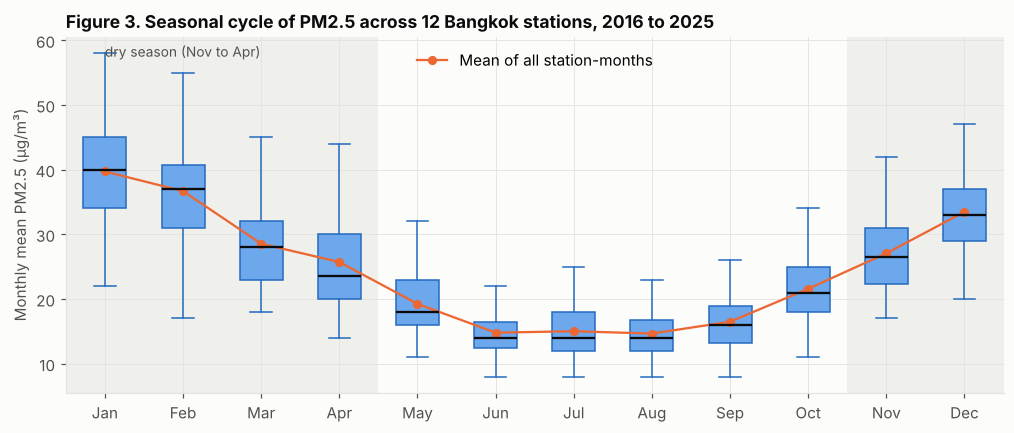

{1: 39.7, 2: 36.7, 3: 28.6, 4: 25.7, 5: 19.3, 6: 14.8, 7: 15.0, 8: 14.7, 9: 16.5, 10: 21.6, 11: 27.1, 12: 33.5}
peak/low ratio: 2.71


In [12]:
mon = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
fig, ax = plt.subplots(figsize=(11, 4.2))
data = [pm[pm.month == m].pm25_mean for m in range(1, 13)]
ax.boxplot(data, positions=range(1, 13), widths=0.55, patch_artist=True, showfliers=False,
           medianprops=dict(color=INK, lw=1.5), boxprops=dict(facecolor=BLUES[2], edgecolor=BLUES[4]),
           whiskerprops=dict(color=BLUES[4]), capprops=dict(color=BLUES[4]))
clim = pm.groupby("month").pm25_mean.mean()
ax.plot(range(1, 13), clim.values, color=C2, marker="o", ms=5, lw=1.5, label="Mean of all station-months")
ax.set_xticks(range(1, 13)); ax.set_xticklabels(mon); ax.set_ylabel("Monthly mean PM2.5 (µg/m³)")
ax.axvspan(0.5, 4.5, color=GRID, alpha=0.5, lw=0); ax.axvspan(10.5, 12.5, color=GRID, alpha=0.5, lw=0)
ax.text(1, ax.get_ylim()[1]*0.95, "dry season (Nov to Apr)", color=INK2, fontsize=9)
ax.legend(loc="upper center")
ax.set_title("Figure 3. Seasonal cycle of PM2.5 across 12 Bangkok stations, 2016 to 2025")
save(fig, "fig03_seasonal_cycle.png")
RESULTS["clim_by_month"] = clim.round(1).to_dict()
RESULTS["peak_month"], RESULTS["low_month"] = int(clim.idxmax()), int(clim.idxmin())
RESULTS["peak_to_low_ratio"] = round(clim.max() / clim.min(), 2)
print(clim.round(1).to_dict()); print("peak/low ratio:", RESULTS["peak_to_low_ratio"])

### 3.4 Year by month heat map (city mean)

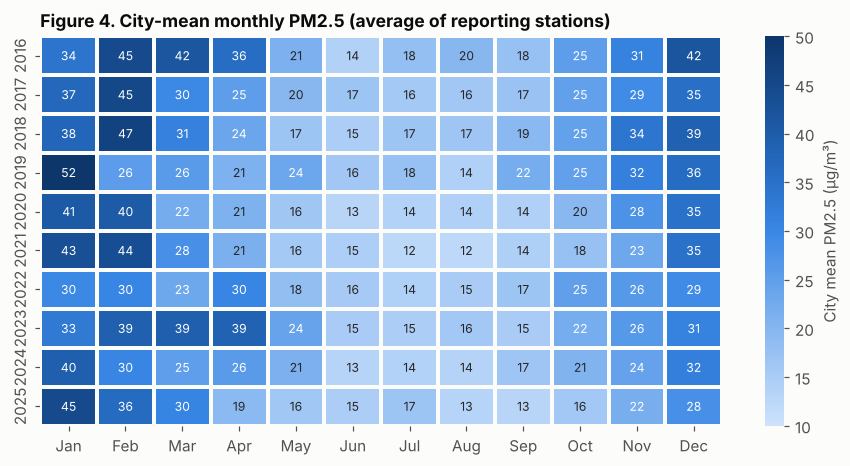

In [13]:
hm = city.pivot_table(index="year", columns="month", values="pm25")
fig, ax = plt.subplots(figsize=(10, 4.6))
sns.heatmap(hm, cmap=SEQ, annot=True, fmt=".0f", annot_kws=dict(size=8), cbar_kws=dict(label="City mean PM2.5 (µg/m³)"),
            linewidths=1.5, linecolor=SURFACE, ax=ax, vmin=10, vmax=50)
ax.set_xticklabels(mon, rotation=0); ax.set_xlabel(""); ax.set_ylabel(""); ax.grid(False)
ax.set_title("Figure 4. City-mean monthly PM2.5 (average of reporting stations)")
save(fig, "fig04_year_month_heatmap.png")

**Reading Figure 4:** January or February is the worst month in every year. January 2019 (52 µg/m³) is the single worst month in the record; 2016 to 2018 had very polluted Februaries; and 2023 is unusual because PM2.5 stayed high (39 µg/m³) through March and April.
Note that 2016 values average fewer stations (Part 2.5), which is why the trend in Part 4 is estimated with station fixed effects.

### 3.5 Candidate drivers: seasonal cycles side by side
Each variable has its own units, so they are drawn as **small multiples** (one panel each) rather than on a shared or dual axis.

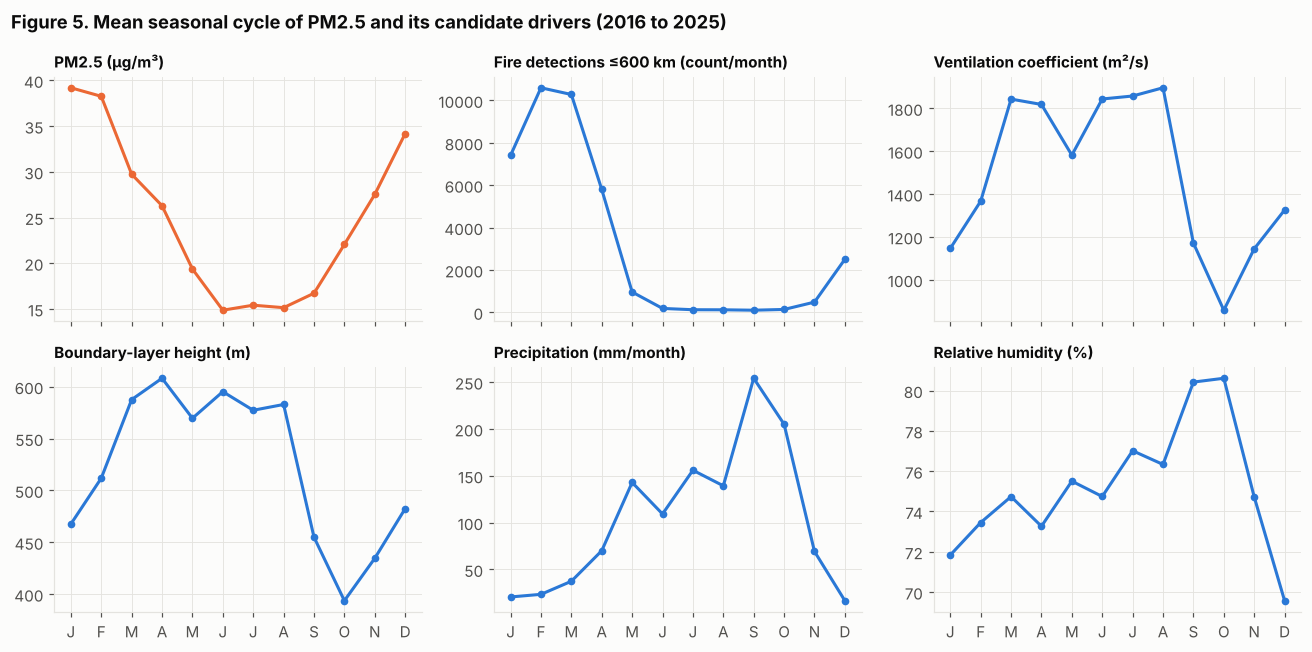

,pm25,fires_600km,vc,blh,precip,rh
month,,,,,,
1,39.2,7407.9,1145.9,467.6,20.6,71.8
2,38.3,10597.7,1366.4,511.8,23.4,73.5
3,29.7,10280.7,1843.3,587.5,37.4,74.7
4,26.3,5799.4,1818.3,608.1,70.0,73.3
5,19.4,959.1,1581.6,569.5,142.9,75.5
6,14.9,185.1,1843.8,595.2,109.2,74.7
7,15.4,123.3,1857.8,577.2,155.9,77.0
8,15.1,120.2,1896.2,582.8,139.3,76.3
9,16.7,100.9,1170.9,454.9,254.1,80.4


In [14]:
cm = city.groupby("month")[["pm25","fires_600km","vc","blh","precip","rh"]].mean()
labels = {"pm25":"PM2.5 (µg/m³)", "fires_600km":"Fire detections ≤600 km (count/month)",
          "vc":"Ventilation coefficient (m²/s)", "blh":"Boundary-layer height (m)",
          "precip":"Precipitation (mm/month)", "rh":"Relative humidity (%)"}
fig, axes = plt.subplots(2, 3, figsize=(12, 6), sharex=True)
for ax, (k, lab) in zip(axes.ravel(), labels.items()):
    ax.plot(range(1, 13), cm[k], color=C2 if k == "pm25" else C1, marker="o", ms=4)
    ax.set_title(lab, fontsize=10); ax.set_xticks(range(1, 13)); ax.set_xticklabels([m[0] for m in mon])
fig.suptitle("Figure 5. Mean seasonal cycle of PM2.5 and its candidate drivers (2016 to 2025)", x=0.01, ha="left", fontweight="bold", color=INK)
fig.tight_layout(); save(fig, "fig05_driver_seasonal_cycles.png")
display(cm.round(1))

**Reading Figure 5:**
* Fires within 600 km peak in **February and March**, while PM2.5 peaks a little earlier, in **January**.
* Ventilation is lowest in **October** and stays low from November to January. In October PM2.5 stays moderate anyway because October is the second-wettest month, and rain removes particles (wet deposition).
* So the January peak lines up with a *combination*: poor ventilation, almost no rain, and fires already rising.

### 3.6 Correlation structure

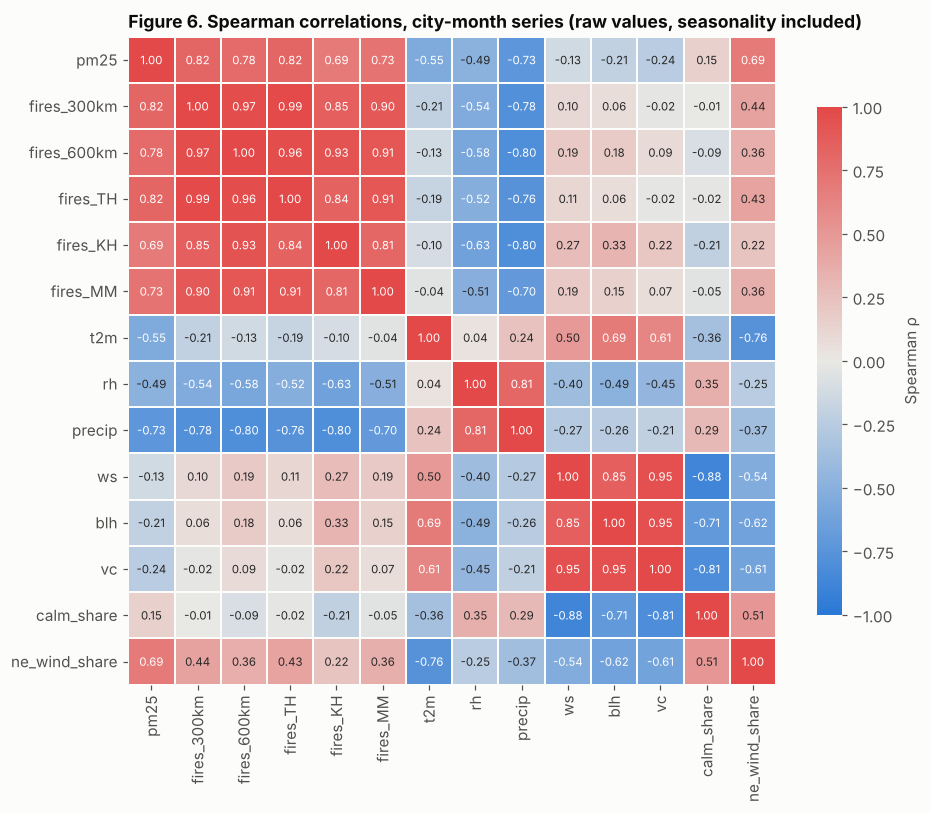

In [15]:
cols = ["pm25","fires_300km","fires_600km","fires_TH","fires_KH","fires_MM","t2m","rh","precip","ws","blh","vc","calm_share","ne_wind_share"]
corr = city[cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(9.5, 8))
sns.heatmap(corr, cmap=DIV, center=0, vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws=dict(size=7.5),
            square=True, linewidths=1, linecolor=SURFACE, cbar_kws=dict(shrink=0.75, label="Spearman ρ"), ax=ax)
ax.grid(False); ax.set_title("Figure 6. Spearman correlations, city-month series (raw values, seasonality included)")
save(fig, "fig06_correlation_matrix.png")

**Caution on Figure 6:** almost every variable here follows the seasons, so raw correlations mostly measure *shared seasonality*. For example, PM2.5 and humidity are both seasonal, but that does not mean humidity lowers PM2.5.
Part 4.4 removes the seasonal cycle and tests the drivers on **anomalies**, which is the scientifically defensible comparison.

---
## Part 4: Data Analysis and Insights Extraction
### 4.1 Roadside vs general-area stations (RQ1)
Comparing the *same months* removes seasonal and year-to-year differences, so any remaining difference is due to station type.

{'mean': np.float64(5.72), 'ci95': [np.float64(5.26), np.float64(6.19)], 'pct': np.float64(25.3), 'n_months': 119, 'share_months_road_higher': np.float64(0.992), 'wilcoxon_p': 2.952842322682829e-21}


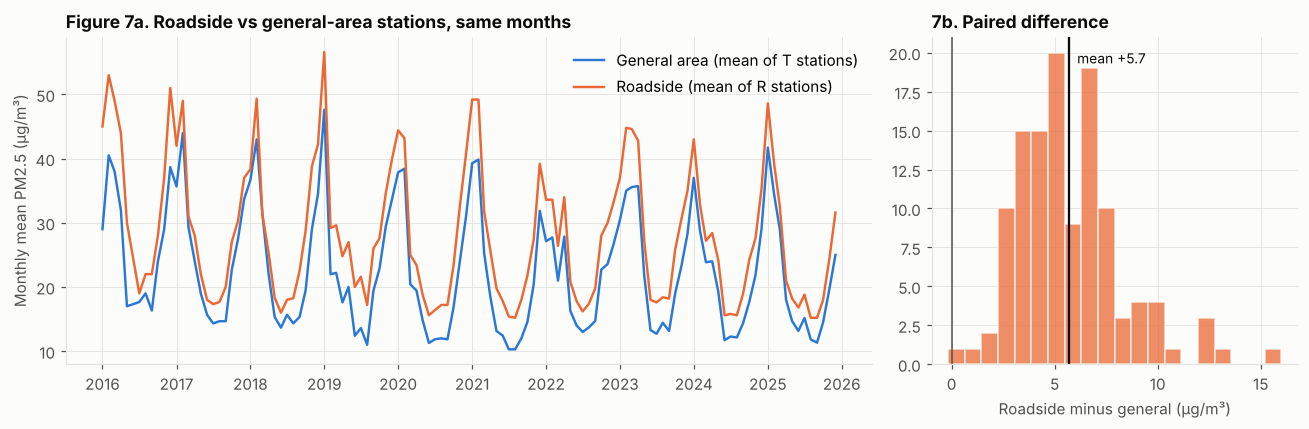

In [16]:
pair = pm.pivot_table(index="date", columns="type", values="pm25_mean", aggfunc="mean").dropna()
diff = pair["Roadside"] - pair["General"]
w = stats.wilcoxon(diff)
rng = np.random.default_rng(42)
boot = np.array([rng.choice(diff.values, len(diff)).mean() for _ in range(10000)])
ci = np.percentile(boot, [2.5, 97.5])
RESULTS["road_minus_general"] = dict(mean=round(diff.mean(), 2), ci95=[round(ci[0], 2), round(ci[1], 2)],
                                     pct=round(100 * diff.mean() / pair["General"].mean(), 1), n_months=int(len(diff)),
                                     share_months_road_higher=round((diff > 0).mean(), 3), wilcoxon_p=float(w.pvalue))
print(RESULTS["road_minus_general"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw=dict(width_ratios=[2.2, 1]))
ax = axes[0]
ax.plot(pair.index, pair["General"], color=C1, lw=1.6, label="General area (mean of T stations)")
ax.plot(pair.index, pair["Roadside"], color=C2, lw=1.6, label="Roadside (mean of R stations)")
ax.set_ylabel("Monthly mean PM2.5 (µg/m³)"); ax.legend(loc="upper right")
ax.set_title("Figure 7a. Roadside vs general-area stations, same months")
ax = axes[1]
ax.hist(diff, bins=20, color=C2, alpha=0.75, edgecolor=SURFACE)
ax.axvline(0, color=INK2, lw=1); ax.axvline(diff.mean(), color=INK, lw=1.5)
ax.text(diff.mean(), ax.get_ylim()[1]*0.92, f"  mean +{diff.mean():.1f}", color=INK, fontsize=9)
ax.set_xlabel("Roadside minus general (µg/m³)"); ax.set_title("7b. Paired difference")
fig.tight_layout(); save(fig, "fig07_roadside_vs_general.png")

### 4.2 Long-term trend (RQ2)
**Model A, station and month fixed effects (all 12 stations):**

$$PM_{s,t} = \alpha_s + \gamma_{m(t)} + \beta\,t + \varepsilon_{s,t}$$

$\alpha_s$ absorbs each station's typical level, $\gamma_m$ absorbs the seasonal cycle, and $\beta$ is the trend in µg/m³ per year. Standard errors are clustered by month (all stations share the same weather in a given month).
A second version replaces $\beta t$ with year dummies, so each year's level can be plotted.

**Model B, robustness check:** a Seasonal Mann-Kendall test with Sen's slope on the mean of the **5 stations that report throughout 2016-07 to 2025-12** (05T, 52R, 54R, 59T, 61T). It is non-parametric and assumes no distribution.

{'slope_per_year': np.float64(-0.571), 'ci95': [-0.828, -0.315], 'p': 1.2558318939859643e-05, 'r2': np.float64(0.788), 'pct_per_decade': np.float64(-23.4)}
{'sen_slope_per_year': np.float64(-0.494), 'p': 4.4394272180614536e-05, 'tau': np.float64(-0.305), 'trend': 'decreasing'}


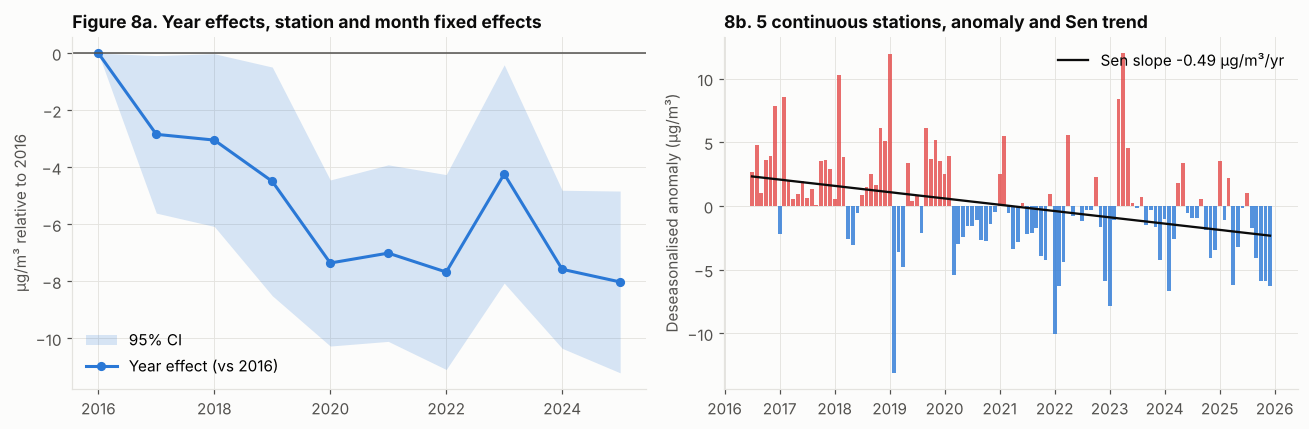

In [17]:
pm["t"] = (pm.year - 2016) + (pm.month - 1) / 12
pm["ym"] = pm.date.dt.strftime("%Y-%m")
mA = smf.ols("pm25_mean ~ C(station_code) + C(month) + t", data=pm).fit(cov_type="cluster", cov_kwds={"groups": pm["ym"]})
b, (lo, hi), p = mA.params["t"], mA.conf_int().loc["t"], mA.pvalues["t"]
mY = smf.ols("pm25_mean ~ C(station_code) + C(month) + C(year)", data=pm).fit(cov_type="cluster", cov_kwds={"groups": pm["ym"]})
yrs = list(range(2016, 2026))
ye = pd.DataFrame({"year": yrs,
                   "effect": [0] + [mY.params[f"C(year)[T.{y}]"] for y in yrs[1:]],
                   "lo": [0] + [mY.conf_int().loc[f"C(year)[T.{y}]", 0] for y in yrs[1:]],
                   "hi": [0] + [mY.conf_int().loc[f"C(year)[T.{y}]", 1] for y in yrs[1:]]})
full5 = ["05T","52R","54R","59T","61T"]
s5 = pm[pm.station_code.isin(full5) & (pm.date >= "2016-07-01")].groupby("date").pm25_mean.mean().reindex(pd.date_range("2016-07-01","2025-12-01",freq="MS"))
smk = mk.seasonal_test(s5.interpolate(limit=2).values, period=12)
RESULTS["trend_fe"] = dict(slope_per_year=round(b, 3), ci95=[round(lo, 3), round(hi, 3)], p=float(p), r2=round(mA.rsquared, 3))
RESULTS["trend_smk"] = dict(sen_slope_per_year=round(smk.slope, 3), p=float(smk.p), tau=round(smk.Tau, 3), trend=smk.trend)
RESULTS["year_effects_vs_2016"] = ye.set_index("year").effect.round(2).to_dict()
mean_level = pm.pm25_mean.mean()
RESULTS["trend_fe"]["pct_per_decade"] = round(100 * 10 * b / mean_level, 1)
print(RESULTS["trend_fe"]); print(RESULTS["trend_smk"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ax = axes[0]
ax.fill_between(ye.year, ye.lo, ye.hi, color=C1, alpha=0.18, lw=0, label="95% CI")
ax.plot(ye.year, ye.effect, color=C1, marker="o", ms=5, label="Year effect (vs 2016)")
ax.axhline(0, color=INK2, lw=1)
ax.set_ylabel("µg/m³ relative to 2016"); ax.legend(loc="lower left")
ax.set_title("Figure 8a. Year effects, station and month fixed effects")
ax = axes[1]
an = s5 - s5.groupby(s5.index.month).transform("mean")
ax.bar(an.index, an.values, width=25, color=np.where(an.values > 0, "#e34948", C1), alpha=0.8)
tt = np.arange(len(an)) / 12
ax.plot(an.index, smk.slope * (tt - tt.mean()), color=INK, lw=1.5, label=f"Sen slope {smk.slope:+.2f} µg/m³/yr")
ax.set_ylabel("Deseasonalised anomaly (µg/m³)"); ax.legend(loc="upper right")
ax.set_title("8b. 5 continuous stations, anomaly and Sen trend")
fig.tight_layout(); save(fig, "fig08_trend.png")

### 4.3 Exceedance and health relevance (RQ4)
* **Thai standards:** 24-hour mean ≤ 37.5 µg/m³ (in force from 1 Jun 2023; 50 µg/m³ before) and annual mean ≤ 15 µg/m³.
* **WHO 2021 Air Quality Guideline:** annual ≤ 5 µg/m³, 24-hour ≤ 15 µg/m³.

For the current standard, I use 2024 to 2025 (both years fully under 37.5 µg/m³).

[np.float64(16.6), np.float64(28.0)] 0.127 [np.float64(18.5), np.float64(74.5)]


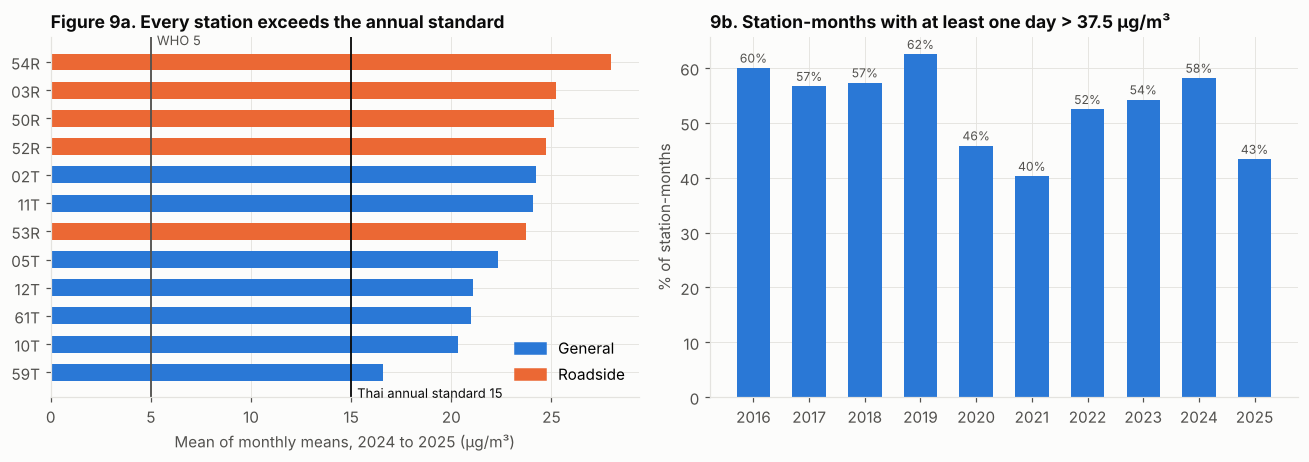

,days_exceed,days_valid,share,per_year
station_code,,,,
02T,118.0,727.0,0.162,59.0
03R,115.0,717.0,0.160,57.5
05T,73.0,708.0,0.103,36.5
10T,62.0,713.0,0.087,31.0
11T,63.0,441.0,0.143,31.5
12T,63.0,697.0,0.090,31.5
50R,109.0,729.0,0.150,54.5
52R,106.0,699.0,0.152,53.0
53R,106.0,717.0,0.148,53.0


In [18]:
recent = pm[pm.year.isin([2024, 2025])]
ann = recent.groupby("station_code").pm25_mean.mean().sort_values()
ex = recent.groupby("station_code")[["days_exceed","days_valid"]].sum()
ex["share"] = ex.days_exceed / ex.days_valid
ex["per_year"] = ex.days_exceed / recent.groupby("station_code").year.nunique()
RESULTS["recent_annual_mean_range"] = [round(ann.min(), 1), round(ann.max(), 1)]
RESULTS["recent_all_stations_above_thai_annual_15"] = bool((ann > 15).all())
RESULTS["recent_exceed_share_days"] = round(ex.days_exceed.sum() / ex.days_valid.sum(), 3)
RESULTS["recent_exceed_days_per_year_range"] = [round(ex.per_year.min(), 1), round(ex.per_year.max(), 1)]
RESULTS["recent_exceed_days_per_year_by_station"] = ex.per_year.round(1).to_dict()
print(RESULTS["recent_annual_mean_range"], RESULTS["recent_exceed_share_days"], RESULTS["recent_exceed_days_per_year_range"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
ax = axes[0]
cols_ = [C2 if s.endswith("R") else C1 for s in ann.index]
ax.barh(ann.index, ann.values, color=cols_, height=0.6)
ax.axvline(15, color=INK, lw=1.2); ax.text(15.3, -0.9, "Thai annual standard 15", fontsize=8.5, color=INK)
ax.axvline(5, color=INK2, lw=1.2); ax.text(5.3, len(ann)-0.4, "WHO 5", fontsize=8.5, color=INK2)
ax.set_xlabel("Mean of monthly means, 2024 to 2025 (µg/m³)")
ax.set_title("Figure 9a. Every station exceeds the annual standard")
ax.legend(handles=[Patch(color=C1, label="General"), Patch(color=C2, label="Roadside")], loc="lower right")
ax = axes[1]
ey = pm.groupby("year").max_over_37_5.mean() * 100
ax.bar(ey.index, ey.values, color=C1, width=0.6)
for x, y in zip(ey.index, ey.values): ax.text(x, y + 1, f"{y:.0f}%", ha="center", fontsize=8, color=INK2)
ax.set_ylabel("% of station-months"); ax.set_xticks(ey.index)
ax.set_title("9b. Station-months with at least one day > 37.5 µg/m³")
fig.tight_layout(); save(fig, "fig09_compliance.png")
RESULTS["share_station_months_max_over_37_5_by_year"] = (ey / 100).round(3).to_dict()
display(ex.round(3))

### 4.4 What drives month-to-month variation? Fires vs meteorology (RQ3)
To avoid the shared-seasonality trap (Part 3.6), every variable is converted to an **anomaly**, its value minus that calendar month's 2016 to 2025 mean:
$x'_{t} = x_t - \bar{x}_{m(t)}$.
A positive PM2.5 anomaly in a given February therefore means "a worse February than usual", and the question becomes whether that same February also had more fires, less wind or less rain than usual.
Fire counts are log-transformed ($\log(1+n)$) because they are highly skewed.

r                                  p  \
subset          All months Dry season (Nov to Apr) All months   
driver                                                          
log_fires_300km      0.366                   0.437      0.000   
log_fires_600km      0.366                   0.452      0.000   
log_fires_TH         0.372                   0.420      0.000   
log_fires_KH         0.286                   0.410      0.002   
log_fires_MM         0.194                   0.231      0.034   
vc                   0.122                   0.072      0.194   
blh                  0.119                   0.044      0.209   
ws                   0.034                   0.003      0.713   
calm_share          -0.013                  -0.021      0.887   
precip              -0.208                  -0.272      0.022   
rh                  -0.245                  -0.233      0.007   
t2m                 -0.054                  -0.146      0.557   
ne_wind_share        0.239                   0.264      0.009   

                                         
subset          Dry season (Nov to Apr)  
driver                                   
log_fires_300km                   0.000  
log_fires_600km                   0.000  
log_fires_TH                      0.001  
log_fires_KH                      0.001  
log_fires_MM                      0.075  
vc                                0.599  
blh                               0.749  
ws                                0.981  
calm_share                        0.873  
precip                            0.035  
rh                                0.073  
t2m                               0.265  
ne_wind_share                     0.041

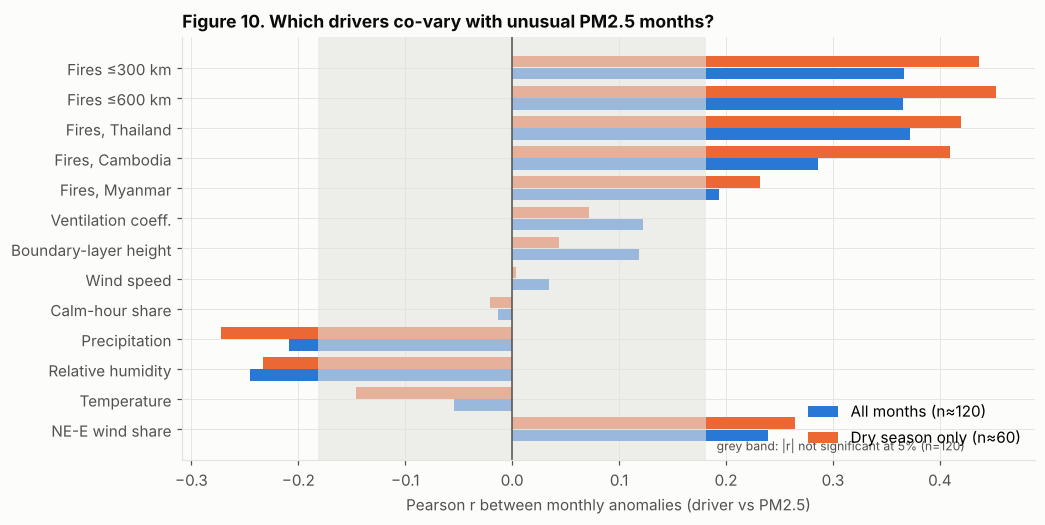

In [19]:
c = city.copy()
for k in ["fires_300km","fires_600km","fires_TH","fires_KH","fires_MM","frp_600km"]:
    c["log_" + k] = np.log1p(c[k])
drivers = ["log_fires_300km","log_fires_600km","log_fires_TH","log_fires_KH","log_fires_MM","vc","blh","ws","calm_share","precip","rh","t2m","ne_wind_share"]
anom = c[["pm25"] + drivers].groupby(c.month).transform(lambda s: s - s.mean())
anom["dry"] = c.month.isin([11, 12, 1, 2, 3, 4])
rows = []
for d in drivers:
    for label, sub in [("All months", anom), ("Dry season (Nov to Apr)", anom[anom.dry])]:
        s = sub[["pm25", d]].dropna()
        r, p = stats.pearsonr(s.pm25, s[d])
        rows.append((d, label, r, p, len(s)))
ac = pd.DataFrame(rows, columns=["driver","subset","r","p","n"])
piv = ac.pivot(index="driver", columns="subset", values="r").loc[drivers]
RESULTS["anomaly_corr"] = piv.round(2).to_dict()
display(ac.pivot(index="driver", columns="subset", values=["r","p"]).round(3).loc[drivers])

nice = {"log_fires_300km":"Fires ≤300 km","log_fires_600km":"Fires ≤600 km","log_fires_TH":"Fires, Thailand","log_fires_KH":"Fires, Cambodia",
        "log_fires_MM":"Fires, Myanmar","vc":"Ventilation coeff.","blh":"Boundary-layer height","ws":"Wind speed","calm_share":"Calm-hour share",
        "precip":"Precipitation","rh":"Relative humidity","t2m":"Temperature","ne_wind_share":"NE-E wind share"}
fig, ax = plt.subplots(figsize=(10, 5))
yy = np.arange(len(drivers))
ax.barh(yy + 0.2, piv["All months"], height=0.38, color=C1, label="All months (n≈120)")
ax.barh(yy - 0.2, piv["Dry season (Nov to Apr)"], height=0.38, color=C2, label="Dry season only (n≈60)")
ax.set_yticks(yy); ax.set_yticklabels([nice[d] for d in drivers]); ax.invert_yaxis()
ax.axvline(0, color=INK2, lw=1)
crit = 1.96 / np.sqrt(120 - 3); ax.axvspan(-crit, crit, color=GRID, alpha=0.6, lw=0)
ax.text(crit + 0.01, len(drivers) - 0.3, "grey band: |r| not significant at 5% (n=120)", fontsize=8, color=INK2)
ax.set_xlabel("Pearson r between monthly anomalies (driver vs PM2.5)")
ax.legend(loc="lower right"); ax.set_title("Figure 10. Which drivers co-vary with unusual PM2.5 months?")
save(fig, "fig10_anomaly_correlations.png")

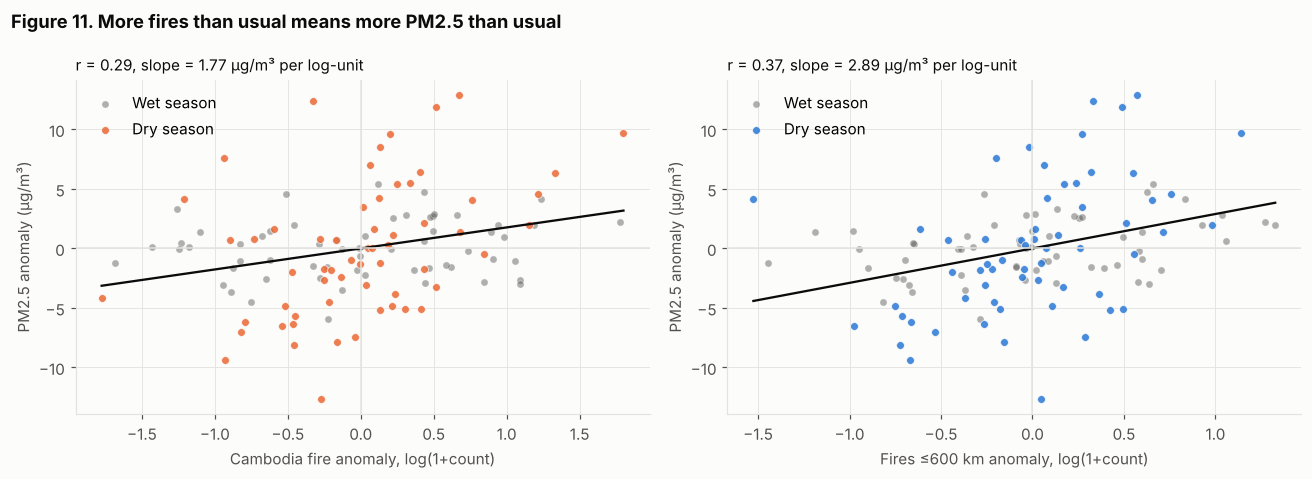

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
for ax, d, col, lab in [(axes[0], "log_fires_KH", C2, "Cambodia fire anomaly, log(1+count)"), (axes[1], "log_fires_600km", C1, "Fires ≤600 km anomaly, log(1+count)")]:
    s = anom[["pm25", d, "dry"]].dropna()
    ax.scatter(s[d][~s.dry], s.pm25[~s.dry], s=22, color=INK2, alpha=0.45, label="Wet season", edgecolor=SURFACE, lw=0.5)
    ax.scatter(s[d][s.dry], s.pm25[s.dry], s=26, color=col, alpha=0.85, label="Dry season", edgecolor=SURFACE, lw=0.5)
    sl, ic, r, p, _ = stats.linregress(s[d], s.pm25)
    xx = np.linspace(s[d].min(), s[d].max(), 50); ax.plot(xx, ic + sl * xx, color=INK, lw=1.5)
    ax.axhline(0, color=GRID, lw=1); ax.axvline(0, color=GRID, lw=1)
    ax.set_xlabel(lab); ax.set_ylabel("PM2.5 anomaly (µg/m³)"); ax.legend(loc="upper left")
    ax.set_title(f"r = {r:.2f}, slope = {sl:.2f} µg/m³ per log-unit", fontsize=10, fontweight="normal")
fig.suptitle("Figure 11. More fires than usual means more PM2.5 than usual", x=0.01, ha="left", fontweight="bold", color=INK)
fig.tight_layout(); save(fig, "fig11_fire_anomaly_scatter.png")

**Multivariable check: regression with month fixed effects.** Correlations can be confounded, for example if fire-heavy months are also dry and calm.
The model below adds fires, dispersion and rain together, with month fixed effects ($\gamma_m$) absorbing the seasonal cycle and HC3 robust standard errors:

$$PM_t = \gamma_{m(t)} + \beta_1 \log(1+\text{Fires}_{600km,t}) + \beta_2\,VC_t + \beta_3\,\text{Rain}_t + \beta_4\,\text{RH}_t + \beta_5\,t + \varepsilon_t$$

$t$ is a linear time trend. The BLH gap removes 6 months (January to June 2024) from this model.

In [21]:
c["t"] = (c.year - 2016) + (c.month - 1) / 12
c["vc_k"] = c.vc / 1000          # 1000 m²/s units for a readable coefficient
c["rain_100"] = c.precip / 100   # per 100 mm
mF = smf.ols("pm25 ~ C(month) + log_fires_600km + vc_k + rain_100 + rh + t", data=c).fit(cov_type="HC3")
mF0 = smf.ols("pm25 ~ C(month) + t", data=c.dropna(subset=["vc_k"])).fit()
tab = pd.DataFrame({"coef": mF.params, "ci_low": mF.conf_int()[0], "ci_high": mF.conf_int()[1], "p": mF.pvalues}).loc[["log_fires_600km","vc_k","rain_100","rh","t"]]
display(tab.round(3))
print(f"R² month FE + trend only = {mF0.rsquared:.3f};  R² with drivers = {mF.rsquared:.3f};  n = {int(mF.nobs)}")
RESULTS["regression_fe"] = dict(coef=tab.coef.round(3).to_dict(), p=tab.p.round(4).to_dict(), r2_base=round(mF0.rsquared, 3), r2_full=round(mF.rsquared, 3), n=int(mF.nobs))
# interpretation: doubling fires multiplies (1+n) by ~2, i.e. +log(2) in log1p
RESULTS["pm_per_fire_doubling"] = round(mF.params["log_fires_600km"] * np.log(2), 2)
print("PM2.5 change for a doubling of fire detections:", RESULTS["pm_per_fire_doubling"], "µg/m³")

# lagged effect: do last month's fires matter after controlling this month's?
c["log_fires_600km_lag1"] = c.log_fires_600km.shift(1)
mL = smf.ols("pm25 ~ C(month) + log_fires_600km + log_fires_600km_lag1 + rain_100 + rh + t", data=c).fit(cov_type="HC3")
print(mL.params[["log_fires_600km","log_fires_600km_lag1"]].round(3).to_dict(), mL.pvalues[["log_fires_600km","log_fires_600km_lag1"]].round(4).to_dict())

,coef,ci_low,ci_high,p
log_fires_600km,1.125,-0.721,2.970,0.232
vc_k,-4.012,-8.305,0.282,0.067
rain_100,-0.419,-2.687,1.849,0.717
rh,-0.669,-1.266,-0.072,0.028
t,-0.696,-1.016,-0.375,0.000


R² month FE + trend only = 0.823;  R² with drivers = 0.857;  n = 114
PM2.5 change for a doubling of fire detections: 0.78 µg/m³
{'log_fires_600km': 1.651, 'log_fires_600km_lag1': -0.471} {'log_fires_600km': 0.0521, 'log_fires_600km_lag1': 0.4859}


**Why does the fire coefficient shrink in the multivariable model? Confounding between fires and weather.**
The month-FE regression gives a smaller and non-significant fire coefficient than the simple anomaly correlation, and the ventilation coefficient changes sign (from weakly positive in Figure 10 to negative here, the physically expected direction).
The table below shows why: months with *more fires than usual* are also *drier* (lower humidity and rain) and have *deeper mixing* (higher VC), because dry, sunny weather both allows burning and deepens the boundary layer.
So a simple correlation credits fires with some of the effect of dry weather, and VC's own diluting effect is hidden by the fires that come with it.

In [22]:
display(anom[["pm25","log_fires_600km","rh","precip","vc"]].corr().round(2))
specs = {"(1) fires only": "pm25 ~ C(month) + log_fires_600km + t",
         "(2) + ventilation": "pm25 ~ C(month) + log_fires_600km + vc_k + t",
         "(3) + rain & humidity": "pm25 ~ C(month) + log_fires_600km + vc_k + rain_100 + rh + t"}
cc = c.dropna(subset=["vc_k"])
rows = []
for k, f_ in specs.items():
    m = smf.ols(f_, data=cc).fit(cov_type="HC3")
    rows.append((k, m.params["log_fires_600km"], m.bse["log_fires_600km"], m.pvalues["log_fires_600km"],
                 m.params.get("vc_k", np.nan), m.pvalues.get("vc_k", np.nan), m.rsquared))
att = pd.DataFrame(rows, columns=["model","fire_coef","fire_se","fire_p","vc_coef","vc_p","R2"]).set_index("model")
display(att.round(3))
RESULTS["fire_coef_attenuation"] = att.round(3).to_dict(orient="index")

,pm25,log_fires_600km,rh,precip,vc
pm25,1.00,0.37,-0.25,-0.21,0.12
log_fires_600km,0.37,1.00,-0.35,-0.43,0.33
rh,-0.25,-0.35,1.00,0.62,-0.61
precip,-0.21,-0.43,0.62,1.00,-0.46
vc,0.12,0.33,-0.61,-0.46,1.00


,fire_coef,fire_se,fire_p,vc_coef,vc_p,R2
model,,,,,,
(1) fires only,2.255,0.825,0.006,NaN,NaN,0.838
(2) + ventilation,2.299,0.878,0.009,-0.246,0.856,0.838
(3) + rain & humidity,1.125,0.942,0.232,-4.012,0.067,0.857


**Interpretation:** on its own, a one-unit rise in log fire count (about 2.7 times as many detections) goes with +2.3 µg/m³ (model 1, p = 0.006), and adding ventilation alone hardly changes it. Once ventilation, rain and humidity are held fixed, the estimate roughly halves and can no longer be separated from zero with 114 months.
The honest conclusion is that **fire activity and dry, stagnant-season weather act together**, and monthly data cannot fully separate them. Daily data with back-trajectories would be needed for attribution.

### 4.5 Season-level view: was a bad dry season a big fire season?

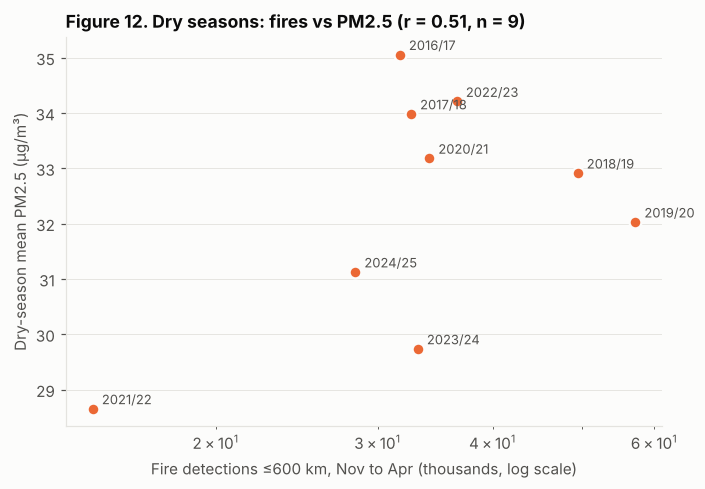

,pm25,fires,n
season,,,
2017,35.055556,31701,6
2018,33.983333,32603,6
2019,32.912963,49503,6
2020,32.027778,57195,6
2021,33.180556,34128,6
2022,28.652778,14687,6
2023,34.207071,36564,6
2024,29.736111,33163,6
2025,31.125000,28352,6


In [23]:
c["season"] = np.where(c.month >= 11, c.year + 1, c.year)     # Nov-Dec belong to the next season's label
ds = c[c.month.isin([11, 12, 1, 2, 3, 4])].groupby("season").agg(pm25=("pm25","mean"), fires=("fires_600km","sum"), n=("pm25","size"))
ds = ds[(ds.n == 6) & (ds.index >= 2017) & (ds.index <= 2025)]     # complete Nov-Apr seasons only
r_s, p_s = stats.pearsonr(np.log(ds.fires), ds.pm25)
RESULTS["season_level"] = dict(r_logfires_pm=round(r_s, 2), p=round(p_s, 3), n=int(len(ds)), table=ds.round(1).reset_index().to_dict(orient="records"))
fig, ax = plt.subplots(figsize=(7, 4.6))
ax.scatter(ds.fires / 1000, ds.pm25, s=60, color=C2, edgecolor=SURFACE, lw=1.5, zorder=3)
for s_, r_ in ds.iterrows(): ax.annotate(f"{s_-1}/{str(s_)[2:]}", (r_.fires / 1000, r_.pm25), xytext=(6, 3), textcoords="offset points", fontsize=8.5, color=INK2)
ax.set_xscale("log"); ax.set_xlabel("Fire detections ≤600 km, Nov to Apr (thousands, log scale)")
ax.set_ylabel("Dry-season mean PM2.5 (µg/m³)")
ax.set_title(f"Figure 12. Dry seasons: fires vs PM2.5 (r = {r_s:.2f}, n = {len(ds)})")
save(fig, "fig12_season_fires_pm.png")
display(ds)

**Reading Figure 12:** the direction is positive: 2021/22, the season with by far the fewest fires, was also the cleanest. The relationship is not tight, though: 2019/20 had the most fires but only middling PM2.5.
With only 9 complete seasons, however, the correlation is **not statistically significant**, so it is shown as supporting evidence, not proof.

---
## Part 5: Data Visualization: summary figure
A single figure that tells the whole story for the presentation: the seasonal cycle, the decline, and the fire link.

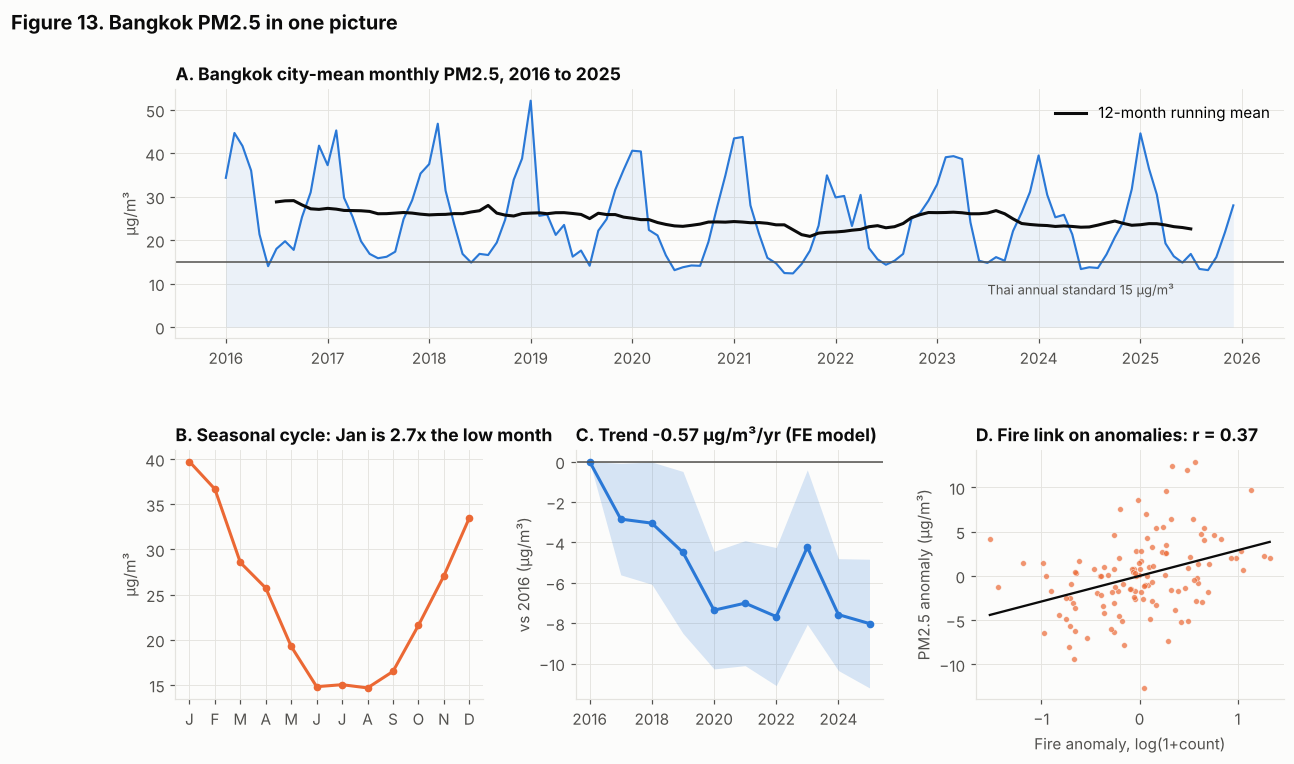

In [24]:
fig = plt.figure(figsize=(13, 7.2))
gs = fig.add_gridspec(2, 3, height_ratios=[1, 1], hspace=0.45, wspace=0.3)
ax = fig.add_subplot(gs[0, :])
cs = city.pm25
ax.plot(cs.index, cs.values, color=C1, lw=1.4)
ax.fill_between(cs.index, cs.values, color=C1, alpha=0.08, lw=0)
roll = cs.rolling(12, center=True, min_periods=12).mean()
ax.plot(roll.index, roll.values, color=INK, lw=2, label="12-month running mean")
ax.axhline(15, color=INK2, lw=1); ax.text(cs.index[-30], 7.5, "Thai annual standard 15 µg/m³", fontsize=8.5, color=INK2)
ax.set_ylabel("µg/m³"); ax.legend(loc="upper right")
ax.set_title("A. Bangkok city-mean monthly PM2.5, 2016 to 2025")
ax = fig.add_subplot(gs[1, 0])
ax.plot(range(1, 13), clim.values, color=C2, marker="o", ms=4); ax.set_xticks(range(1, 13)); ax.set_xticklabels([m[0] for m in mon])
ax.set_title(f"B. Seasonal cycle: Jan is {RESULTS['peak_to_low_ratio']:.1f}x the low month"); ax.set_ylabel("µg/m³")
ax = fig.add_subplot(gs[1, 1])
ax.fill_between(ye.year, ye.lo, ye.hi, color=C1, alpha=0.18, lw=0); ax.plot(ye.year, ye.effect, color=C1, marker="o", ms=4)
ax.axhline(0, color=INK2, lw=1); ax.set_title(f"C. Trend {RESULTS['trend_fe']['slope_per_year']:+.2f} µg/m³/yr (FE model)"); ax.set_ylabel("vs 2016 (µg/m³)")
ax = fig.add_subplot(gs[1, 2])
s = anom[["pm25","log_fires_600km"]].dropna()
ax.scatter(s.log_fires_600km, s.pm25, s=14, color=C2, alpha=0.7, edgecolor=SURFACE, lw=0.4)
sl, ic, r, p, _ = stats.linregress(s.log_fires_600km, s.pm25); xx = np.linspace(s.log_fires_600km.min(), s.log_fires_600km.max(), 20)
ax.plot(xx, ic + sl * xx, color=INK, lw=1.5)
ax.set_xlabel("Fire anomaly, log(1+count)"); ax.set_ylabel("PM2.5 anomaly (µg/m³)")
ax.set_title(f"D. Fire link on anomalies: r = {r:.2f}")
fig.suptitle("Figure 13. Bangkok PM2.5 in one picture", x=0.01, ha="left", fontweight="bold", color=INK, fontsize=13)
save(fig, "fig13_summary.png")

---
## Part 6: Basic Machine Learning (optional): predicting monthly station PM2.5
**Task:** predict a station's monthly mean PM2.5 from information available without the monitor: season, station type and identity, ERA5 meteorology and regional fire counts.

**Validation design:** random K-fold splitting leaks information in time series, because neighbouring months are similar. I therefore use
1. a **hold-out on the future**: train on 2016 to 2023, test on 2024 to 2025;
2. **rolling-origin evaluation**: train up to year Y−1, test on year Y, for Y = 2021 to 2025.

**Baseline to beat:** each station's 2016 to 2023 average for that calendar month (*climatology*). A model is only useful if it beats this.
BLH and VC are left out of the feature set because of the 2024 data gap, which falls inside the test period.

In [25]:
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.linear_model import RidgeCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.inspection import permutation_importance

D = panel.copy()
D["msin"], D["mcos"] = np.sin(2*np.pi*D.month/12), np.cos(2*np.pi*D.month/12)
D["roadside"] = (D.type == "Roadside").astype(int)
for k in ["fires_300km","fires_600km","fires_TH","fires_KH","fires_MM"]: D["log_" + k] = np.log1p(D[k])
st_d = pd.get_dummies(D.station_code, prefix="st", dtype=int); D = pd.concat([D, st_d], axis=1)
FEATS = ["msin","mcos","roadside","t2m","rh","precip","ws","calm_share","ne_wind_share",
         "log_fires_300km","log_fires_600km","log_fires_TH","log_fires_KH","log_fires_MM"] + list(st_d.columns)
D = D.dropna(subset=FEATS + ["pm25_mean"])

def models():
    return {"Ridge regression": make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-3, 3, 40))),
            "Random forest": RandomForestRegressor(n_estimators=600, min_samples_leaf=3, max_features=0.5, random_state=42, n_jobs=-1),
            "Gradient boosting": HistGradientBoostingRegressor(max_depth=3, learning_rate=0.05, max_iter=300, l2_regularization=1.0, random_state=42)}

def evaluate(train, test):
    climo = train.groupby(["station_code","month"]).pm25_mean.mean().rename("clim")
    t = test.join(climo, on=["station_code","month"]).dropna(subset=["clim"])
    out, preds = {}, {"Climatology baseline": t.clim.values}
    for name, m in models().items():
        m.fit(train[FEATS], train.pm25_mean); preds[name] = m.predict(t[FEATS])
    for name, p in preds.items():
        out[name] = dict(RMSE=root_mean_squared_error(t.pm25_mean, p), MAE=mean_absolute_error(t.pm25_mean, p), R2=r2_score(t.pm25_mean, p))
    return pd.DataFrame(out).T, t, preds

train, test = D[D.year <= 2023], D[D.year >= 2024]
res, tt, preds = evaluate(train, test)
print(f"Train: {len(train)} station-months (2016 to 2023), Test: {len(tt)} station-months (2024 to 2025)")
display(res.round(3))
RESULTS["ml_holdout"] = res.round(3).to_dict(orient="index")

Train: 883 station-months (2016 to 2023), Test: 277 station-months (2024 to 2025)


,RMSE,MAE,R2
Climatology baseline,4.826,3.768,0.741
Ridge regression,4.689,3.760,0.756
Random forest,4.149,3.439,0.809
Gradient boosting,5.531,4.390,0.660


In [26]:
roll = []
for Y in range(2021, 2026):
    r_, _, _ = evaluate(D[D.year < Y], D[D.year == Y])
    r_["test_year"] = Y; roll.append(r_.reset_index().rename(columns={"index": "model"}))
roll = pd.concat(roll)
summary = roll.groupby("model")[["RMSE","MAE","R2"]].mean().sort_values("RMSE")
display(roll.pivot(index="test_year", columns="model", values="RMSE").round(2))
display(summary.round(3))
RESULTS["ml_rolling_mean"] = summary.round(3).to_dict(orient="index")
best = summary.index[0]; print("Best by mean rolling RMSE:", best)

model,Climatology baseline,Gradient boosting,Random forest,Ridge regression
test_year,,,,
2021,4.97,4.66,4.38,4.08
2022,6.50,4.99,4.52,5.66
2023,7.43,6.36,6.67,6.89
2024,4.01,5.36,4.02,4.21
2025,5.26,5.51,4.13,4.80


,RMSE,MAE,R2
model,,,
Random forest,4.744,3.611,0.749
Ridge regression,5.128,3.978,0.689
Gradient boosting,5.375,4.160,0.678
Climatology baseline,5.633,4.291,0.624


Best by mean rolling RMSE: Random forest


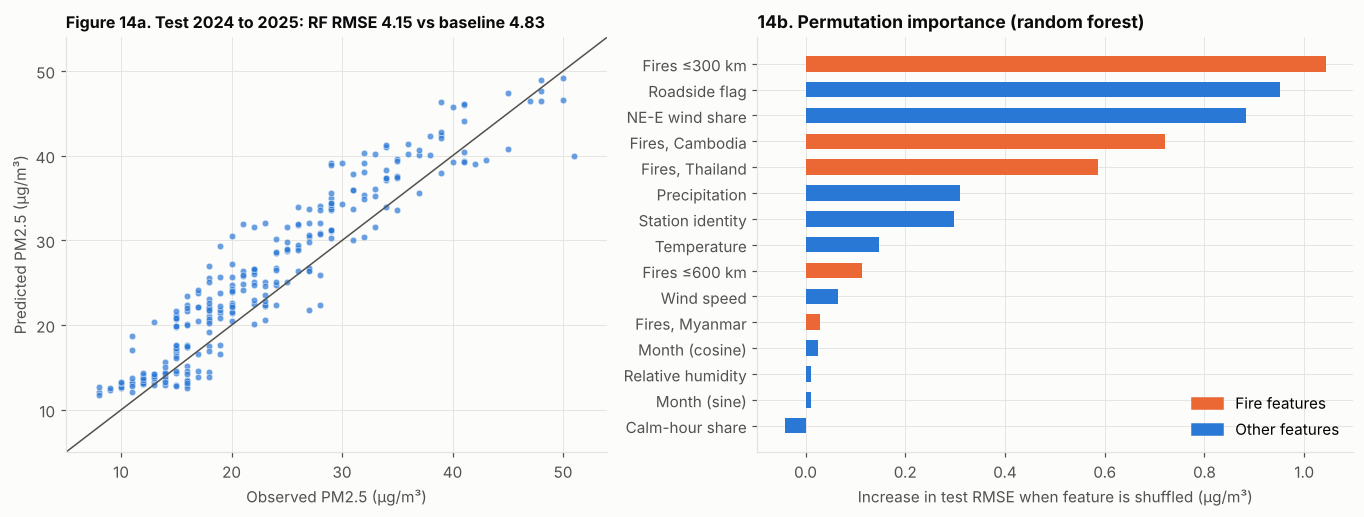

In [27]:
rf = models()["Random forest"].fit(train[FEATS], train.pm25_mean)
pi = permutation_importance(rf, tt[FEATS], tt.pm25_mean, n_repeats=30, random_state=0, scoring="neg_root_mean_squared_error")
imp = pd.Series(pi.importances_mean, index=FEATS)
# group the 12 station dummies into one "station identity" feature for readability
grp = imp[[f for f in FEATS if not f.startswith("st_")]].copy()
Xp = tt[FEATS].copy(); rng = np.random.default_rng(0); base_rmse = root_mean_squared_error(tt.pm25_mean, rf.predict(Xp)); drops = []
for _ in range(30):
    Xs = Xp.copy(); perm = rng.permutation(len(Xs)); Xs[list(st_d.columns)] = Xs[list(st_d.columns)].values[perm]
    drops.append(root_mean_squared_error(tt.pm25_mean, rf.predict(Xs)) - base_rmse)
grp["station identity (12 dummies)"] = np.mean(drops)
names = {"msin":"Month (sine)","mcos":"Month (cosine)","roadside":"Roadside flag","t2m":"Temperature","rh":"Relative humidity","precip":"Precipitation",
         "ws":"Wind speed","calm_share":"Calm-hour share","ne_wind_share":"NE-E wind share","log_fires_300km":"Fires ≤300 km","log_fires_600km":"Fires ≤600 km",
         "log_fires_TH":"Fires, Thailand","log_fires_KH":"Fires, Cambodia","log_fires_MM":"Fires, Myanmar","station identity (12 dummies)":"Station identity"}
grp = grp.rename(index=names).sort_values()
RESULTS["rf_permutation_importance_rmse_increase"] = grp.sort_values(ascending=False).round(3).to_dict()

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8), gridspec_kw=dict(width_ratios=[1, 1.1]))
ax = axes[0]
p_rf = preds["Random forest"]
ax.scatter(tt.pm25_mean, p_rf, s=18, color=C1, alpha=0.7, edgecolor=SURFACE, lw=0.4, label="Random forest")
lim = [5, max(tt.pm25_mean.max(), p_rf.max()) + 3]; ax.plot(lim, lim, color=INK2, lw=1)
ax.set_xlim(lim); ax.set_ylim(lim); ax.set_xlabel("Observed PM2.5 (µg/m³)"); ax.set_ylabel("Predicted PM2.5 (µg/m³)")
rr = res.loc["Random forest"]; rb = res.loc["Climatology baseline"]
ax.set_title(f"Figure 14a. Test 2024 to 2025: RF RMSE {rr.RMSE:.2f} vs baseline {rb.RMSE:.2f}", fontsize=10.5)
ax = axes[1]
ax.barh(grp.index, grp.values, color=[C2 if "Fire" in n else C1 for n in grp.index], height=0.6)
ax.set_xlabel("Increase in test RMSE when feature is shuffled (µg/m³)")
ax.set_title("14b. Permutation importance (random forest)")
ax.legend(handles=[Patch(color=C2, label="Fire features"), Patch(color=C1, label="Other features")], loc="lower right")
fig.tight_layout(); save(fig, "fig14_ml_results.png")

---
## Environmental interpretation

In [28]:
R = RESULTS
print(f"Seasonality: January mean {R['clim_by_month'][1]} vs low month ({R['low_month']}) {R['clim_by_month'][R['low_month']]} µg/m³, ratio {R['peak_to_low_ratio']}x")
print(f"Roadside excess: +{R['road_minus_general']['mean']} µg/m³ (95% CI {R['road_minus_general']['ci95']}), roadside higher in {100*R['road_minus_general']['share_months_road_higher']:.0f}% of months")
print(f"Trend (FE): {R['trend_fe']['slope_per_year']} µg/m³/yr, 95% CI {R['trend_fe']['ci95']}, about {R['trend_fe']['pct_per_decade']}% per decade; Seasonal MK Sen slope {R['trend_smk']['sen_slope_per_year']} (p={R['trend_smk']['p']:.1e})")
print(f"Fires: doubling detections within 600 km is associated with +{R['pm_per_fire_doubling']} µg/m³ (month FE model); season-level r = {R['season_level']['r_logfires_pm']}")
print(f"Compliance 2024 to 2025: station means {R['recent_annual_mean_range']} µg/m³ vs Thai 15 / WHO 5; {100*R['recent_exceed_share_days']:.1f}% of valid station-days > 37.5")
with open(os.path.join(ROOT, "results.json"), "w") as fh:
    json.dump(RESULTS, fh, indent=2, default=float)
print("Saved results.json")

Seasonality: January mean 39.7 vs low month (8) 14.7 µg/m³, ratio 2.71x
Roadside excess: +5.72 µg/m³ (95% CI [np.float64(5.26), np.float64(6.19)]), roadside higher in 99% of months
Trend (FE): -0.571 µg/m³/yr, 95% CI [-0.828, -0.315], about -23.4% per decade; Seasonal MK Sen slope -0.494 (p=4.4e-05)
Fires: doubling detections within 600 km is associated with +0.78 µg/m³ (month FE model); season-level r = 0.51
Compliance 2024 to 2025: station means [np.float64(16.6), np.float64(28.0)] µg/m³ vs Thai 15 / WHO 5; 12.7% of valid station-days > 37.5
Saved results.json


1. **Bangkok's PM2.5 problem is a dry-season problem.** The January mean (39.7 µg/m³) is 2.7 times the August low (14.7 µg/m³).
   The peak coincides with the north-east monsoon, which brings dry, cool air, a shallow boundary layer and almost no rain. In October ventilation is even poorer, yet PM2.5 stays moderate, which shows how much **wet deposition** (rain-out) protects the city in the wet season.
2. **Traffic adds a persistent local layer.** Roadside stations average **+5.7 µg/m³ (95 % CI 5.3 to 6.2)** more than general-area stations in the *same month*, about 25 % more, and are higher in 99 % of months.
   This local increment comes from vehicle exhaust (especially diesel), resuspended road dust and street-canyon trapping, and it is the part that city measures (low-emission zones, diesel controls, bus electrification) can reduce directly.
3. **Regional burning makes bad seasons worse, together with dry weather.** After removing the seasonal cycle, months with more fire detections than usual have higher PM2.5 (r = 0.37 for all months, 0.45 in the dry season, p < 0.001), and fire counts are the most important extra predictor in the random forest.
   But fire-heavy months are also unusually dry, and when humidity, rain and ventilation are controlled the fire effect roughly halves and is no longer statistically separable. Fires and dry, stable weather act **together**, so action is needed on both local emissions and provincial and **transboundary** crop-residue and forest burning (the ASEAN Agreement on Transboundary Haze Pollution framework).
4. **The air is improving, but not fast enough.** Controlling for season and for which stations were reporting, PM2.5 fell by **0.57 µg/m³ per year (95 % CI 0.32 to 0.83)**, about 23 % per decade. The non-parametric Seasonal Mann-Kendall test on the five continuous stations agrees (Sen slope −0.49 µg/m³/yr, p < 0.001).
   Even so, in 2024 to 2025 **every station's mean (16.6 to 28.0 µg/m³) exceeded the Thai annual standard of 15 µg/m³**, all were 3 to 6 times the WHO guideline of 5 µg/m³, and 12.7 % of valid station-days (about 1 in 8) exceeded the 24-hour standard of 37.5 µg/m³.
5. **Weather and fire data improve monthly prediction, but only modestly.** The random forest reduces error against the seasonal baseline both on 2024 to 2025 (RMSE 4.15 vs 4.83 µg/m³) and in rolling-origin testing (mean RMSE 4.74 vs 5.63 µg/m³).
   Fires within 300 km, the roadside flag and the share of north-east to east winds are its most informative inputs. Better forecasts need *daily* data, where stagnation events and smoke transport can be resolved.

### Limitations
* **Monthly resolution.** PCD's public long-term record is monthly, so day-scale processes (inversions, single smoke episodes) are averaged out. This is the most likely reason the ventilation coefficient shows only a weak link here, even though its physical role is well established.
* **One meteorology grid cell** represents the whole city, and ERA5 has a BLH gap from January to July 2024.
* **Fire counts** measure detections, not emissions. Small, short or cloud-covered fires are missed, and burnt area and fuel type differ by region.
* **Correlation is not attribution.** Source apportionment (chemical speciation) or a chemical-transport model would be needed to quantify each source's share.
* **The standard change** in 2023 means raw exceedance counts are not comparable across that date; this analysis uses consistent metrics instead.

### Recommendations
* Prioritise **traffic emission controls** at roadside hot spots (54R Din Daeng, 03R Kanchanaphisek, 50R Rama IV).
* Use **regional fire counts** (FIRMS, freely available within hours) as an early-warning input to Bangkok's dust-forecast system, especially from **January to March**.
* Pursue **transboundary cooperation** on agricultural burning, since the strongest single fire signal comes from outside Thailand.
* Publish **daily** station data as open CSV, which would allow much stronger analysis than the PDF-only archive.